In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("pratyushpuri/financial-news-market-events-dataset-2025")

print("Path to dataset files:", path)

100%|██████████| 408k/408k [00:00<00:00, 19.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/pratyushpuri/financial-news-market-events-dataset-2025/versions/1


In [2]:
import os
import pandas as pd

# List all files in the downloaded directory to locate the dataset file
files = os.listdir(path)
print("Files in dataset:", files)

csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    target_file = os.path.join(path, csv_files[0])
    df = pd.read_csv(target_file)
    # Select and display the first 5 columns
    first_five_cols = df.iloc[:, :5]
    print("\nFirst 5 columns preview:")
    display(first_five_cols.head())
else:
    print("No CSV file found. Please check the listed files above.")

Files in dataset: ['financial_news_events.csv', 'financial_news_events.json', 'financial_news_events.xlsx']

First 5 columns preview:


,Date,Headline,Source,Market_Event,Market_Index
0,2025-05-21,Nikkei 225 index benefits from a weaker yen,Times of India,Commodity Price Shock,DAX
1,2025-05-18,Government subsidy program gives a lift to the...,Financial Times,Central Bank Meeting,Shanghai Composite
2,2025-06-25,New housing data release shows a slowdown in m...,The Hindu Business Line,Consumer Confidence Report,Shanghai Composite
3,2025-07-21,Massive stock buyback program announced by a c...,The Economist,Commodity Price Shock,NSE Nifty
4,2025-07-23,Government spending bill is expected to stimul...,The Motley Fool,Inflation Data Release,Nasdaq Composite


In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Drop any rows where the critical 'Headline' field is NaN
df = df.dropna(subset=['Headline']).reset_index(drop=True)

# Download necessary NLTK data including the required punkt_tab
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_and_lemmatize(text):
    if not isinstance(text, str):
        return ""
    # Remove HTML tags (if any)
    text = re.sub(r'<[^>]+>', '', text)
    # Convert to lowercase and remove non-alphabetic characters
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    # Tokenize
    tokens = word_tokenize(text)
    # Remove stop words and lemmatize
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(cleaned_tokens)

# Apply text cleaning
df['Cleaned_Headline'] = df['Headline'].apply(clean_and_lemmatize)

# Preview the results
display(df[['Headline', 'Cleaned_Headline']].head())

,Headline,Cleaned_Headline
0,Nikkei 225 index benefits from a weaker yen,nikkei index benefit weaker yen
1,Government subsidy program gives a lift to the...,government subsidy program give lift agricultu...
2,New housing data release shows a slowdown in m...,new housing data release show slowdown market ...
3,Massive stock buyback program announced by a c...,massive stock buyback program announced consum...
4,Government spending bill is expected to stimul...,government spending bill expected stimulate ec...


In [4]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import pandas as pd

# Sanity Check 1: Ensure there are no missing values in the raw 'Headline' column
missing_headlines = df['Headline'].isnull().sum()
print(f"[Sanity Check] Missing raw headlines: {missing_headlines}")
if missing_headlines > 0:
    df = df.dropna(subset=['Headline']).reset_index(drop=True)
    print("Dropped rows with missing headlines.")

# Download the VADER lexicon
nltk.download('vader_lexicon', quiet=True)

# Initialize the VADER Sentiment Intensity Analyzer
sia = SentimentIntensityAnalyzer()

# Calculate sentiment scores on the raw 'Headline' column
def get_vader_sentiment(text):
    if not isinstance(text, str):
        return pd.Series([0.0, 'Neutral'])
    scores = sia.polarity_scores(text)
    # Classify based on compound score
    if scores['compound'] >= 0.05:
        sentiment = 'Positive'
    elif scores['compound'] <= -0.05:
        sentiment = 'Negative'
    else:
        sentiment = 'Neutral'
    return pd.Series([scores['compound'], sentiment])

# Apply sentiment analysis on the raw 'Headline' column
df[['VADER_Compound', 'VADER_Sentiment']] = df['Headline'].apply(get_vader_sentiment)

# Sanity Check 2: Confirm both generated columns are completely populated
null_compound = df['VADER_Compound'].isnull().sum()
null_sentiment = df['VADER_Sentiment'].isnull().sum()
print(f"[Sanity Check] Nulls in VADER_Compound: {null_compound}")
print(f"[Sanity Check] Nulls in VADER_Sentiment: {null_sentiment}")

# Display the clean results
display(df[['Headline', 'VADER_Compound', 'VADER_Sentiment']].head(10))

[Sanity Check] Missing raw headlines: 0
[Sanity Check] Nulls in VADER_Compound: 0
[Sanity Check] Nulls in VADER_Sentiment: 0


,Headline,VADER_Compound,VADER_Sentiment
0,Nikkei 225 index benefits from a weaker yen,-0.0772,Negative
1,Government subsidy program gives a lift to the...,0.0000,Neutral
2,New housing data release shows a slowdown in m...,0.0000,Neutral
3,Massive stock buyback program announced by a c...,0.0000,Neutral
4,Government spending bill is expected to stimul...,0.2263,Positive
5,Central bank maintains status quo on interest ...,0.4588,Positive
6,Tech Giant's New Product Launch Sparks Sector-...,0.3400,Positive
7,A massive data breach sends a tech company's s...,0.0000,Neutral
8,Market sentiment turns positive on vaccine tri...,0.5574,Positive
9,"Global trade talks collapse, causing market tu...",-0.6908,Negative


In [5]:
# Print all columns in the dataset to locate a target category column
print("Columns in the dataset:")
print(df.columns.tolist())

# Display a sample of the potential category columns to understand the labels available
display(df.head(3))

Columns in the dataset:
['Date', 'Headline', 'Source', 'Market_Event', 'Market_Index', 'Index_Change_Percent', 'Trading_Volume', 'Sentiment', 'Sector', 'Impact_Level', 'Related_Company', 'News_Url', 'Cleaned_Headline', 'VADER_Compound', 'VADER_Sentiment']


,Date,Headline,Source,Market_Event,Market_Index,Index_Change_Percent,Trading_Volume,Sentiment,Sector,Impact_Level,Related_Company,News_Url,Cleaned_Headline,VADER_Compound,VADER_Sentiment
0,2025-05-21,Nikkei 225 index benefits from a weaker yen,Times of India,Commodity Price Shock,DAX,3.52,166.45,NaN,Technology,High,Goldman Sachs,https://timesofindia.indiatimes.com/business/m...,nikkei index benefit weaker yen,-0.0772,Negative
1,2025-05-18,Government subsidy program gives a lift to the...,Financial Times,Central Bank Meeting,Shanghai Composite,-3.39,57.61,NaN,Retail,Low,ExxonMobil,https://timesofindia.indiatimes.com/business/m...,government subsidy program give lift agricultu...,0.0000,Neutral
2,2025-06-25,New housing data release shows a slowdown in m...,The Hindu Business Line,Consumer Confidence Report,Shanghai Composite,-0.05,403.22,Neutral,Retail,Medium,Boeing,https://www.moneycontrol.com/us-markets/sp-500,new housing data release show slowdown market ...,0.0000,Neutral


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# Drop rows where 'Sector' is missing
classification_df = df.dropna(subset=['Sector', 'Cleaned_Headline']).copy()

# Features and target variable
X = classification_df['Cleaned_Headline']
y = classification_df['Sector']

# Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Convert text features using TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Naive Bayes Classifier
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_tfidf, y_train)

# Make predictions
y_pred = nb_classifier.predict(X_test_tfidf)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Naive Bayes Classification Accuracy: {accuracy:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Naive Bayes Classification Accuracy: 5.90%

Classification Report:
                       precision    recall  f1-score   support

  Aerospace & Defense       0.06      0.06      0.06        31
          Agriculture       0.07      0.09      0.08        35
           Automotive       0.06      0.06      0.06        34
         Construction       0.04      0.03      0.04        30
       Consumer Goods       0.00      0.00      0.00        30
               Energy       0.04      0.03      0.04        32
              Finance       0.06      0.07      0.06        29
           Healthcare       0.19      0.13      0.16        30
          Industrials       0.00      0.00      0.00        34
            Materials       0.00      0.00      0.00        33
Media & Entertainment       0.09      0.09      0.09        32
      Pharmaceuticals       0.07      0.10      0.08        29
          Real Estate       0.04      0.06      0.05        32
               Retail       0.08      0.03      0.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:
# Inspect a few headlines alongside their labeled sectors
display(df[['Headline', 'Sector']].head(15))

,Headline,Sector
0,Nikkei 225 index benefits from a weaker yen,Technology
1,Government subsidy program gives a lift to the...,Retail
2,New housing data release shows a slowdown in m...,Retail
3,Massive stock buyback program announced by a c...,Consumer Goods
4,Government spending bill is expected to stimul...,Consumer Goods
5,Central bank maintains status quo on interest ...,Transportation
6,Tech Giant's New Product Launch Sparks Sector-...,Telecommunications
7,A massive data breach sends a tech company's s...,Retail
8,Market sentiment turns positive on vaccine tri...,Energy
9,"Global trade talks collapse, causing market tu...",Transportation


### Data quality check


In [8]:
# How many distinct headlines are there, and are the dataset's own labels consistent?
n_rows = len(df)
n_unique = df['Headline'].nunique()
print(f"Rows with a headline: {n_rows}")
print(f"Distinct headlines:   {n_unique}")

labelled = df.dropna(subset=['Sentiment'])
labels_per_headline = labelled.groupby('Headline')['Sentiment'].nunique()
print(f"Headlines carrying more than one Sentiment label: {(labels_per_headline > 1).sum()} of {len(labels_per_headline)}")

sectors_per_headline = df.groupby('Headline')['Sector'].nunique()
print(f"Average number of different Sector labels per headline: {sectors_per_headline.mean():.1f}")

print("\nMean index change by dataset Sentiment label:")
print(df.groupby('Sentiment')['Index_Change_Percent'].mean().round(3))

Rows with a headline: 2876
Distinct headlines:   50
Headlines carrying more than one Sentiment label: 50 of 50
Average number of different Sector labels per headline: 17.3

Mean index change by dataset Sentiment label:
Sentiment
Negative   -0.062
Neutral     0.114
Positive   -0.107
Name: Index_Change_Percent, dtype: float64


- The same headline is tagged with every sentiment and with many different sectors, so the dataset's `Sentiment` and `Sector` columns behave like random labels. That is why the sector classifier above scores about chance.
- Because rows are repeats of a few dozen headlines, a random train/test split puts identical text on both sides. From here on, anything that is split or retrieved uses **one row per distinct headline**.
- Plan: use VADER for sentiment (no labels needed), keyword rules to define topic categories, and a small hand-labelled set to sanity-check both.

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# Map the dataset's original 18 'Sector' values (which the check above shows are unreliable)
# into our 5 cleaner target categories. This avoids rule-based labeling, but cannot fix random labels.
sector_mapping = {
    'Finance': 'Banking & Central Banks',
    'Technology': 'Tech Stocks & Software',
    'Telecommunications': 'Tech Stocks & Software',
    'Real Estate': 'Real Estate',
    'Construction': 'Real Estate',
    'Energy': 'Energy & Commodities',
    'Utilities': 'Energy & Commodities',
    'Materials': 'Energy & Commodities',
    'Agriculture': 'Trade & Macro Economy',
    'Transportation': 'Trade & Macro Economy',
    'Retail': 'Trade & Macro Economy',
    'Consumer Goods': 'Trade & Macro Economy',
    'Healthcare': 'Other / Services',
    'Pharmaceuticals': 'Other / Services',
    'Aerospace & Defense': 'Other / Services',
    'Industrials': 'Other / Services',
    'Media & Entertainment': 'Other / Services',
    'Automotive': 'Other / Services'
}

# Apply mapping to the original, non-rule 'Sector' column
corrected_df = df.dropna(subset=['Sector', 'Cleaned_Headline']).copy()
corrected_df['Mapped_Category'] = corrected_df['Sector'].map(sector_mapping)

# Sanity Check: Drop rows where Mapped_Category is NaN
corrected_df = corrected_df.dropna(subset=['Mapped_Category']).reset_index(drop=True)

# Features & Targets
X_real = corrected_df['Cleaned_Headline']
y_real = corrected_df['Mapped_Category']

# Split into training and testing sets
X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42, stratify=y_real
)

# Vectorize text
real_vectorizer = TfidfVectorizer(max_features=2500, ngram_range=(1, 2))
X_train_tfidf_real = real_vectorizer.fit_transform(X_train_real)
X_test_tfidf_real = real_vectorizer.transform(X_test_real)

# Train Naive Bayes Classifier
real_nb = MultinomialNB(alpha=0.5)
real_nb.fit(X_train_tfidf_real, y_train_real)

# Predict and evaluate
y_pred_real = real_nb.predict(X_test_tfidf_real)
accuracy_real = accuracy_score(y_test_real, y_pred_real)

print(f"Realistic Naive Bayes Accuracy (Mapped from original Sector labels): {accuracy_real:.2%}\n")
print("Classification Report:")
print(classification_report(y_test_real, y_pred_real))

Realistic Naive Bayes Accuracy (Mapped from original Sector labels): 25.52%

Classification Report:
                         precision    recall  f1-score   support

Banking & Central Banks       0.00      0.00      0.00        29
   Energy & Commodities       0.19      0.09      0.12        97
       Other / Services       0.32      0.47      0.38       189
            Real Estate       0.06      0.05      0.05        63
 Tech Stocks & Software       0.20      0.06      0.09        66
  Trade & Macro Economy       0.23      0.32      0.27       132

               accuracy                           0.26       576
              macro avg       0.17      0.17      0.15       576
           weighted avg       0.22      0.26      0.22       576



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [10]:
# Compare the mapped-sector result with a "always guess the biggest class" baseline
majority = y_test_real.value_counts(normalize=True).max()
print(f"Majority-class baseline: {majority:.2%}")
print(f"Naive Bayes on mapped sectors: {accuracy_real:.2%}")

Majority-class baseline: 32.81%
Naive Bayes on mapped sectors: 25.52%


### Keyword rules + Naive Bayes


In [11]:
import re
import pandas as pd

CATEGORY_RULES = [
    ('Real Estate',
     r"\b(housing|real estate|propert\w*|mortgage\w*|homebuilder\w*)\b"),
    ('Tech Stocks & Software',
     r"\b(tech\w*|software|ipo|cyber\w*|data breach|semiconductor\w*|crypto\w*|chip\w*|ai|artificial intelligence)\b"),
    ('Energy & Commodities',
     r"\b(oil|gas|commodit\w*|gold|energy|crude|mining|renewable\w*)\b"),
    ('Banking & Central Banks',
     r"\b(bank\w*|fed|federal reserve|central bank\w*|rates?|interest|monetary|inflation|yields?|bonds?|financ\w*|lend\w*)\b"),
    ('Trade & Macro Economy',
     r"\b(trade|tariff\w*|subsid\w*|spending|gdp|econom\w*|tax\w*|unemployment|recession|export\w*|"
     r"manufacturing|supply chain|retail sales|consumer confidence|geopolitical)\b"),
]
DEFAULT_CATEGORY = 'General Markets'

def match_category_rule(text):
    # Category with the most keyword hits wins; ties go to the earlier rule
    lowered = (text or '').lower()
    best, best_hits = None, 0
    for name, pattern in CATEGORY_RULES:
        hits = len(re.findall(pattern, lowered))
        if hits > best_hits:
            best, best_hits = name, hits
    return best

def assign_financial_category(text):
    return match_category_rule(text) or DEFAULT_CATEGORY

# One row per distinct headline
articles = df.groupby('Headline', sort=False).size().rename('Row_Count').reset_index()
articles['Cleaned_Headline'] = articles['Headline'].map(clean_and_lemmatize)
articles['Category'] = articles['Headline'].map(assign_financial_category)

print(f"Distinct headlines: {len(articles)}")
print(articles['Category'].value_counts())

Distinct headlines: 50
Category
Trade & Macro Economy      15
General Markets            11
Banking & Central Banks    11
Tech Stocks & Software      6
Energy & Commodities        6
Real Estate                 1
Name: count, dtype: int64


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, f1_score

def make_category_pipeline():
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
        ('nb', MultinomialNB(alpha=0.5)),
    ])

X_cat, y_cat = articles['Cleaned_Headline'], articles['Category']

# Leave-one-headline-out cross-validation (each distinct headline is tested once, never trained on)
loo_pred = cross_val_predict(make_category_pipeline(), X_cat, y_cat, cv=LeaveOneOut())
print(f"Leave-one-headline-out accuracy: {accuracy_score(y_cat, loo_pred):.2%}")
print(f"Macro F1: {f1_score(y_cat, loo_pred, average='macro', zero_division=0):.2f}\n")
print(classification_report(y_cat, loo_pred, zero_division=0))

# Final model used by the app, trained on all distinct headlines
category_model = make_category_pipeline().fit(X_cat, y_cat)

Leave-one-headline-out accuracy: 36.00%
Macro F1: 0.20

                         precision    recall  f1-score   support

Banking & Central Banks       0.56      0.45      0.50        11
   Energy & Commodities       0.00      0.00      0.00         6
        General Markets       0.18      0.18      0.18        11
            Real Estate       0.00      0.00      0.00         1
 Tech Stocks & Software       0.00      0.00      0.00         6
  Trade & Macro Economy       0.37      0.73      0.49        15

               accuracy                           0.36        50
              macro avg       0.18      0.23      0.20        50
           weighted avg       0.27      0.36      0.30        50



### Independent sanity check: hand-labelled sentences
Cross-validation on rule labels cannot show whether the categories or the sentiment scores make sense. This small set of **24 sentences written and labelled by the author** (not taken from the dataset) gives an independent, if tiny, check. Treat the numbers as a sanity check, not a benchmark.

The deployed category logic is: keyword rules first; if none fires, use the Naive Bayes prediction only when its confidence is at least 0.5; otherwise `General Markets`. The model is trained on only a few dozen headlines, so it is deliberately not trusted blindly.

In [13]:
gold_df = pd.DataFrame([
    ('The Federal Reserve raised interest rates by a quarter point and warned that more hikes may follow.', 'Negative', 'Banking & Central Banks'),
    ('Regional lender reports record quarterly profit as loan demand strengthens.', 'Positive', 'Banking & Central Banks'),
    ('European Central Bank holds rates steady and says inflation is cooling.', 'Positive', 'Banking & Central Banks'),
    ('Bank shares slump after regulators propose tougher capital rules.', 'Negative', 'Banking & Central Banks'),
    ('Chipmaker unveils faster processor, sending technology shares to a record high.', 'Positive', 'Tech Stocks & Software'),
    ('Cloud software company cuts its annual forecast after customers delay purchases.', 'Negative', 'Tech Stocks & Software'),
    ('Startup behind a popular payments app files for an IPO after rapid user growth.', 'Positive', 'Tech Stocks & Software'),
    ('Hackers breached a major social network, exposing millions of user records.', 'Negative', 'Tech Stocks & Software'),
    ('Home sales fall for the third straight month as mortgage rates stay high.', 'Negative', 'Real Estate'),
    ('Builders report stronger demand for new homes as lending costs ease.', 'Positive', 'Real Estate'),
    ('Commercial property values stabilise after a two-year decline.', 'Neutral', 'Real Estate'),
    ('Crude oil jumps after producers agree to deeper output cuts.', 'Neutral', 'Energy & Commodities'),
    ('Gold slips as the dollar strengthens and investors favour stocks.', 'Negative', 'Energy & Commodities'),
    ('Natural gas prices tumble on mild weather and record storage.', 'Negative', 'Energy & Commodities'),
    ('Solar and wind developers see orders surge under new government incentives.', 'Positive', 'Energy & Commodities'),
    ('Global trade volumes rebound as tariffs on key goods are lifted.', 'Positive', 'Trade & Macro Economy'),
    ('Unemployment ticks up and economists warn of a looming recession.', 'Negative', 'Trade & Macro Economy'),
    ('Manufacturing output was flat last month, in line with forecasts.', 'Neutral', 'Trade & Macro Economy'),
    ('Government unveils tax cuts and a spending package to support growth.', 'Positive', 'Trade & Macro Economy'),
    ('Airline stocks rally as fuel costs fall and summer bookings rise.', 'Positive', 'General Markets'),
    ("Drugmaker's trial misses its main goal, sending shares sharply lower.", 'Negative', 'General Markets'),
    ("Retailer's quarterly earnings match analyst estimates.", 'Neutral', 'General Markets'),
    ('Shares were little changed in quiet trading ahead of the holiday.', 'Neutral', 'General Markets'),
    ('Automaker recalls thousands of vehicles over a braking defect.', 'Negative', 'General Markets')
], columns=['text', 'sentiment', 'category'])

# --- sentiment: VADER on raw text, averaged per sentence for multi-sentence input ---
import numpy as np

def label_from_compound(c):
    return 'Positive' if c >= 0.05 else 'Negative' if c <= -0.05 else 'Neutral'

def vader_sentiment(text):
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', (text or '').strip()) if s]
    if not sentences:
        return 0.0, 'Neutral'
    compound = float(np.mean([sia.polarity_scores(s)['compound'] for s in sentences]))
    return round(compound, 4), label_from_compound(compound)

# --- category: rules first, then Naive Bayes only when confident ---
MODEL_CONFIDENCE_THRESHOLD = 0.5   # chosen up front, not tuned on the gold set

def predict_category(text, model=None):
    model = model or category_model
    proba = model.predict_proba([clean_and_lemmatize(text)])[0]
    best = int(proba.argmax())
    model_category, confidence = str(model.classes_[best]), float(proba[best])
    rule_category = match_category_rule(text)
    if rule_category:
        category, source = rule_category, 'rules'
    elif confidence >= MODEL_CONFIDENCE_THRESHOLD:
        category, source = model_category, 'model'
    else:
        category, source = DEFAULT_CATEGORY, 'default'
    return {'category': category, 'category_source': source,
            'model_category': model_category, 'model_confidence': round(confidence, 3)}

sent_pred = [vader_sentiment(t)[1] for t in gold_df['text']]
rule_pred = [assign_financial_category(t) for t in gold_df['text']]
ml_pred = category_model.predict([clean_and_lemmatize(t) for t in gold_df['text']])
deployed_pred = [predict_category(t)['category'] for t in gold_df['text']]

print(f"Gold set size: {len(gold_df)}")
print(f"VADER sentiment accuracy:          {accuracy_score(gold_df['sentiment'], sent_pred):.2%}")
print(f"Category, rules only:              {accuracy_score(gold_df['category'], rule_pred):.2%}")
print(f"Category, Naive Bayes only:        {accuracy_score(gold_df['category'], ml_pred):.2%}")
print(f"Category, as deployed (rules+NB):  {accuracy_score(gold_df['category'], deployed_pred):.2%}")

errors = gold_df.assign(vader=sent_pred, predicted_category=deployed_pred)
display(errors[(errors['sentiment'] != errors['vader']) | (errors['category'] != errors['predicted_category'])])

Gold set size: 24
VADER sentiment accuracy:          54.17%
Category, rules only:              87.50%
Category, Naive Bayes only:        41.67%
Category, as deployed (rules+NB):  87.50%


,text,sentiment,category,vader,predicted_category
0,The Federal Reserve raised interest rates by a...,Negative,Banking & Central Banks,Positive,Banking & Central Banks
2,European Central Bank holds rates steady and s...,Positive,Banking & Central Banks,Neutral,Banking & Central Banks
3,Bank shares slump after regulators propose tou...,Negative,Banking & Central Banks,Positive,Banking & Central Banks
7,"Hackers breached a major social network, expos...",Negative,Tech Stocks & Software,Negative,General Markets
8,Home sales fall for the third straight month a...,Negative,Real Estate,Positive,Real Estate
9,Builders report stronger demand for new homes ...,Positive,Real Estate,Positive,Banking & Central Banks
10,Commercial property values stabilise after a t...,Neutral,Real Estate,Positive,Real Estate
11,Crude oil jumps after producers agree to deepe...,Neutral,Energy & Commodities,Negative,Energy & Commodities
12,Gold slips as the dollar strengthens and inves...,Negative,Energy & Commodities,Positive,Energy & Commodities
13,Natural gas prices tumble on mild weather and ...,Negative,Energy & Commodities,Positive,Energy & Commodities


### LLM Integration: data, helpers and prompts
The LLM stage runs **after** the NLP stage. For Q&A without a pasted article, the context comes from the **distinct** dataset headlines (one row each), retrieved by TF-IDF similarity to the question instead of "the first 15 rows that contain a keyword". Prompts use the model's chat template, and the NLP results (sentiment, topic) are passed to the model as a hint.

In [14]:
def clean_for_llm(text):
    # Light cleaning that keeps punctuation and sentence structure for the LLM
    if not isinstance(text, str):
        return ""
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

# Distinct headlines are the retrieval pool for Q&A and insights (no duplicates, so no repeated context)
articles['LLM_Clean_Headline'] = articles['Headline'].map(clean_for_llm)
context_pool = articles[['Headline', 'LLM_Clean_Headline', 'Category']].reset_index(drop=True)

print(f"Headlines available as LLM context: {len(context_pool)}")
display(context_pool.head())

Headlines available as LLM context: 50


,Headline,LLM_Clean_Headline,Category
0,Nikkei 225 index benefits from a weaker yen,Nikkei 225 index benefits from a weaker yen,General Markets
1,Government subsidy program gives a lift to the...,Government subsidy program gives a lift to the...,Trade & Macro Economy
2,New housing data release shows a slowdown in m...,New housing data release shows a slowdown in m...,Real Estate
3,Massive stock buyback program announced by a c...,Massive stock buyback program announced by a c...,General Markets
4,Government spending bill is expected to stimul...,Government spending bill is expected to stimul...,Trade & Macro Economy


In [15]:
!pip install -q transformers accelerate ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 39.3 MB/s eta 0:00:00


In [16]:
import torch
from transformers import pipeline

# Initialize a text generation pipeline using a lightweight, open instruction-tuned model
print("Loading Hugging Face pipeline (this may take a minute)... ")
generator = pipeline("text-generation", model="TinyLlama/TinyLlama-1.1B-Chat-v1.0", dtype=torch.bfloat16, device_map="auto")
print("Pipeline loaded successfully!")

Loading Hugging Face pipeline (this may take a minute)... 


config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

Pipeline loaded successfully!


In [17]:
import random
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DISCLAIMER = ("For information only. This is not financial or investment advice, and the output may be "
              "inaccurate or biased. Verify with primary sources.")
SYSTEM_PROMPT = ("You are a careful financial news assistant. Use ONLY the context provided. If the context "
                 "does not contain the answer, say so. Be concise and never give investment advice.")
MAX_ARTICLE_CHARS = 1500   # keeps prompts inside TinyLlama's 2,048-token context

INSIGHT_EXAMPLE_CONTEXT = ("Central bank holds rates steady. Inflation data comes in hotter than expected. "
                           "Bank shares dip on weaker loan demand.")
INSIGHT_EXAMPLE_ANSWER = ("- Rates are unchanged, but hot inflation raises the chance of rates staying high.\n"
                          "- Banks are under pressure from weaker lending demand.\n"
                          "- Watch the next inflation release for any policy shift.")

def truncate_text(text, limit=MAX_ARTICLE_CHARS):
    text = (text or '').strip()
    if len(text) <= limit:
        return text
    cut = text[:limit]
    end = max(cut.rfind('. '), cut.rfind('! '), cut.rfind('? '))
    return cut[:end + 1] if end > limit * 0.5 else cut

def tidy_output(text):
    # Remove chat tokens and repeated lines (small models like to loop)
    text = re.sub(r'<\|[^|>]*\|>|</s>', '', text or '').strip()
    seen, lines = set(), []
    for line in text.splitlines():
        key = line.strip().lower()
        if key and key in seen:
            continue
        seen.add(key)
        lines.append(line.rstrip())
    return re.sub(r'\n{3,}', '\n\n', '\n'.join(lines)).strip()

def chat(messages, max_new_tokens=200, temperature=0.3):
    prompt = generator.tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    kwargs = dict(max_new_tokens=max_new_tokens, return_full_text=False, repetition_penalty=1.15,
                  pad_token_id=generator.tokenizer.eos_token_id)
    if temperature > 0:
        kwargs.update(do_sample=True, temperature=temperature, top_p=0.9)
    else:
        kwargs.update(do_sample=False)
    return tidy_output(generator(prompt, **kwargs)[0]['generated_text'])

# ---- retrieval over distinct headlines -------------------------------------------------
retriever_vec = TfidfVectorizer(preprocessor=clean_and_lemmatize)
retriever_matrix = retriever_vec.fit_transform(context_pool['LLM_Clean_Headline'])

def retrieve_headlines(query, k=5):
    scores = cosine_similarity(retriever_vec.transform([query]), retriever_matrix)[0]
    order = scores.argsort()[::-1][:k]
    return [context_pool['LLM_Clean_Headline'][i] for i in order if scores[i] > 0]

# ---- NLP stage (runs first) -------------------------------------------------------------
INSTITUTIONS = ['Federal Reserve', 'European Central Bank', 'ECB', 'Bank of Japan', 'Bank of England',
                'IMF', 'World Bank', 'OPEC', 'SEC']
entity_terms = {
    'companies': sorted(df['Related_Company'].dropna().unique()),
    'indices': sorted(df['Market_Index'].dropna().unique()),
    'institutions': INSTITUTIONS,
}

def find_entities(text, terms=entity_terms):
    found = {}
    for kind, names in terms.items():
        found[kind] = [n for n in names
                       if re.search(r'(?<!\w)' + re.escape(n) + r'(?!\w)', text, flags=re.IGNORECASE)]
    return found

def analyze_article(text):
    text = (text or '').strip()
    if not text:
        raise ValueError('No text to analyze.')
    compound, label = vader_sentiment(text)
    return {'sentiment': label, 'score': compound, **predict_category(text),
            'entities': find_entities(text), 'word_count': len(text.split())}

def nlp_hint(analysis):
    if not analysis:
        return ''
    return (f"Automated analysis: sentiment is {analysis['sentiment'].lower()} "
            f"(score {analysis['score']:+.2f}); topic is {analysis['category']}.\n")

# ---- LLM stage ---------------------------------------------------------------------------
def summarize_text(text, analysis=None):
    if not text or not text.strip():
        return 'No text provided to summarize.'
    user = f"{nlp_hint(analysis)}Article:\n{truncate_text(text)}\n\nSummarize the article in 2-3 sentences."
    return chat([{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': user}],
                max_new_tokens=120)

def ask_about_headlines(query, article=None, analysis=None):
    if article and article.strip():
        context = truncate_text(article)
    else:
        hits = retrieve_headlines(query, k=5)
        if not hits:
            return 'I could not find headlines related to that question in the dataset.'
        context = '\n'.join(f'- {h}' for h in hits)
    user = f"{nlp_hint(analysis)}Context:\n{context}\n\nQuestion: {query}"
    return chat([{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': user}],
                max_new_tokens=160)

def generate_trading_insights(article=None, analysis=None, few_shot=True):
    if article and article.strip():
        context = truncate_text(article)
    else:
        sample = random.Random(42).sample(list(context_pool['LLM_Clean_Headline']), 12)
        context = '\n'.join(f'- {h}' for h in sample)
    task = 'List 3 short bullet-point takeaways for a market analyst.'
    messages = [{'role': 'system', 'content': SYSTEM_PROMPT}]
    if few_shot:
        messages += [{'role': 'user', 'content': f'Context:\n{INSIGHT_EXAMPLE_CONTEXT}\n\n{task}'},
                     {'role': 'assistant', 'content': INSIGHT_EXAMPLE_ANSWER}]
    messages.append({'role': 'user', 'content': f'{nlp_hint(analysis)}Context:\n{context}\n\n{task}'})
    return chat(messages, max_new_tokens=220, temperature=0.4)

In [18]:
# Curated finance texts (used by the demos and the widget interface)
curated_texts = {
    "Select a curated article...": "",
    "Federal Reserve Statement": "The Federal Reserve kept interest rates unchanged but signaled that borrowing costs will stay higher for longer. Inflation remains elevated, and the job market continues to show resilience. Investors worry about a potential slowdown in real estate as mortgage rates climb.",
    "Tech Sector Expansion": "Tech giants announced a series of new artificial intelligence chips, triggering a sector-wide stock rally. Analysts express optimism regarding software and semiconductor companies, although cybersecurity risks and data breaches remain a prominent threat to market stability.",
    "Oil Price Volatility": "Crude oil prices fell to a multi-year low today amid supply gluts and flagging global trade volume. Safe-haven assets like gold surged in response as investors rotate out of cyclical commodities and equities.",
    "Bank Merger Collapses": "Merger talks between two regional banks fell through after regulators raised concerns about capital requirements. Shares of both lenders dropped, and analysts said the failed deal could slow consolidation across the banking sector.",
    "Housing Market Cools": "New housing data shows home sales slowed for a third month as mortgage rates stayed high. Builders reported weaker demand, though some analysts expect a recovery if the central bank begins cutting rates later this year.",
}

# NLP stage on every sample article: sentiment, topic and mentions in one table
rows = []
for title, text in curated_texts.items():
    if not text:
        continue
    a = analyze_article(text)
    mentions = a['entities']['companies'] + a['entities']['indices'] + a['entities']['institutions']
    rows.append({'Article': title, 'Sentiment': a['sentiment'], 'Score': a['score'],
                 'Category': a['category'], 'Source': a['category_source'],
                 'Mentions': ', '.join(mentions) or '-'})
display(pd.DataFrame(rows))

,Article,Sentiment,Score,Category,Source,Mentions
0,Federal Reserve Statement,Negative,-0.0635,Banking & Central Banks,rules,Federal Reserve
1,Tech Sector Expansion,Positive,0.2770,Tech Stocks & Software,rules,-
2,Oil Price Volatility,Negative,-0.1032,Energy & Commodities,rules,-
3,Bank Merger Collapses,Negative,-0.1366,Banking & Central Banks,rules,-
4,Housing Market Cools,Negative,-0.2997,Banking & Central Banks,rules,-


### LLM demos: Q&A, insights and summary
Each demo calls the NLP stage first (`analyze_article`) and passes its result to the LLM stage. Small models are not deterministic, so wording will vary between runs.

In [19]:
question = "What are the main risks or market trends mentioned regarding interest rates?"
print(f"Question: {question}\n")
print("Retrieved context:")
for h in retrieve_headlines(question):
    print(" -", h)
print("\nAnswer:\n" + ask_about_headlines(question))

Question: What are the main risks or market trends mentioned regarding interest rates?

Retrieved context:
 - Central bank maintains status quo on interest rates
 - Real Estate sector shows signs of overheating as interest rates fall
 - Central Bank's dovish tone hints at future rate cuts
 - New regulations on cryptocurrencies cause a market dip
 - Market braces for a major policy announcement from the EU


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'top_p', 'repetition_penalty', 'pad_token_id', 'temperature', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer LlamaTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to f


Answer:
The main risks or market trends mentioned in the given context include:

1. Central bank maintaining its status quo on interest rates despite rising inflation and slow economic growth.
2. Signs of overheating in the real estate sector due to falling interest rates.
3. Dovish tone by central banks hinting at potential future rate cuts.
4. Cryptocurrency regulation causing a market dip.
5. Major policy announcement from the European Union expected soon.


In [20]:
article = curated_texts["Tech Sector Expansion"]
analysis = analyze_article(article)
print("Generating insights...\n")
print(generate_trading_insights(article, analysis))
print("\n" + DISCLAIMER)

[transformers] Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating insights...

- Sentiment remains positive, with an overall score of +0.28.
- The tech sector is being driven by AI chips announcements, which have triggered a rally among software and semiconductor companies.
- Cybersecurity and data breach concerns continue to be a significant risk factor for market stability.

For information only. This is not financial or investment advice, and the output may be inaccurate or biased. Verify with primary sources.


In [21]:
article = curated_texts["Federal Reserve Statement"]
analysis = analyze_article(article)
print("Original text:\n", article)
print("\nNLP stage:", analysis['sentiment'], f"({analysis['score']:+.2f}),", analysis['category'])
print("\nSummary:\n" + summarize_text(article, analysis))
print("\n" + DISCLAIMER)

[transformers] Both `max_new_tokens` (=120) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original text:
 The Federal Reserve kept interest rates unchanged but signaled that borrowing costs will stay higher for longer. Inflation remains elevated, and the job market continues to show resilience. Investors worry about a potential slowdown in real estate as mortgage rates climb.

NLP stage: Negative (-0.06), Banking & Central Banks

Summary:
Federal Reserve keeps interest rates steady, signaling prolonged economic uncertainty. Economic indicators remain strong despite inflation concerns. Real estate may face a potential slowdown due to rising mortgage rates. Sentiment is negative while topic is Banking & Central Banks.

For information only. This is not financial or investment advice, and the output may be inaccurate or biased. Verify with primary sources.


### Prompting strategy comparison
Same article, same model, two prompt styles: **zero-shot** (instruction only) versus **few-shot** (one worked example before the real request). Compare format, relevance and grounding in the text, then note which you prefer.

In [22]:
article = curated_texts["Oil Price Volatility"]
analysis = analyze_article(article)
for label, flag in [("Zero-shot", False), ("Few-shot (one example)", True)]:
    print(f"=== {label} ===")
    print(generate_trading_insights(article, analysis, few_shot=flag))
    print()

[transformers] Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== Zero-shot ===


[transformers] Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


1. Crude oil prices dropped significantly due to supply glut and flagging global trade volume.
2. Safe-haven assets such as gold rose in response to investor rotation away from cyclical commodities and equities.
3. The short bullet-point takeaways provide a high-level overview of the given context.

=== Few-shot (one example) ===
- Crude oil prices have fallen by over 2% since yesterday's close.
- Global trade volumes have declined by 6.5%, which has contributed to the drop in crude prices.
- Gold prices have risen due to safe haven demand.
- The current trend suggests that investors are moving away from cyclical commodities and into safer assets such as gold.



In [23]:
import html
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# UI elements
text_selector = widgets.Dropdown(options=list(curated_texts.keys()), description='Curated Text:', style={'description_width': 'initial'})
article_area = widgets.Textarea(placeholder='Paste your financial article here...', layout=widgets.Layout(width='90%', height='120px'), description='Article text:', style={'description_width': 'initial'})
query_input = widgets.Text(placeholder='Ask a question (e.g., What are the main risks?)', layout=widgets.Layout(width='90%'), description='Your Query:', style={'description_width': 'initial'})

analyze_button = widgets.Button(description='Analyze', button_style='info')
summary_button = widgets.Button(description='Summarize', button_style='warning')
ask_button = widgets.Button(description='Ask LLM', button_style='primary')
insight_button = widgets.Button(description='Generate Insights', button_style='success')
output_area = widgets.Output()

def on_text_select(change):
    if change['new'] in curated_texts:
        article_area.value = curated_texts[change['new']]

text_selector.observe(on_text_select, names='value')

def analysis_html(a):
    names = a['entities']['companies'] + a['entities']['indices'] + a['entities']['institutions']
    return (f"<div style='border:1px solid #ccc;padding:8px;margin-bottom:8px'>"
            f"<b>Sentiment:</b> {a['sentiment']} (score {a['score']:+.2f}) &nbsp; "
            f"<b>Category:</b> {html.escape(a['category'])} ({a['category_source']}) &nbsp; "
            f"<b>Mentions:</b> {html.escape(', '.join(names) or 'none found')}</div>")

def llm_html(title, body):
    return (f"<h4>{title}</h4><div style='white-space:pre-wrap'>{html.escape(body)}</div>"
            f"<p style='color:gray;font-size:smaller'>{html.escape(DISCLAIMER)}</p>")

def run_widget(kind):
    with output_area:
        clear_output()
        article = article_area.value.strip()
        query = query_input.value.strip()
        if kind == 'ask' and not query:
            print('Please enter a question.')
            return
        if kind in ('analyze', 'summarize') and not article:
            print('Paste or select an article first.')
            return
        analysis = analyze_article(article) if article else None   # NLP stage first
        if analysis:
            display(HTML(analysis_html(analysis)))
        if kind == 'analyze':
            return
        print('Working...')
        if kind == 'summarize':
            out = llm_html('Summary', summarize_text(article, analysis))
        elif kind == 'ask':
            out = llm_html('Answer', ask_about_headlines(query, article, analysis))
        else:
            out = llm_html('Key takeaways', generate_trading_insights(article or None, analysis))
        clear_output()
        if analysis:
            display(HTML(analysis_html(analysis)))
        display(HTML(out))

analyze_button.on_click(lambda b: run_widget('analyze'))
summary_button.on_click(lambda b: run_widget('summarize'))
ask_button.on_click(lambda b: run_widget('ask'))
insight_button.on_click(lambda b: run_widget('insights'))

display(HTML("<h3>Financial QA & Insight Workspace</h3>"))
display(text_selector)
display(article_area)
display(query_input)
display(widgets.HBox([analyze_button, summary_button, ask_button, insight_button]))
display(output_area)

Dropdown(description='Curated Text:', options=('Select a curated article...', 'Federal Reserve Statement', 'Te…

Textarea(value='', description='Article text:', layout=Layout(height='120px', width='90%'), placeholder='Paste…

Text(value='', description='Your Query:', layout=Layout(width='90%'), placeholder='Ask a question (e.g., What …

Output()

### Sentiment over time (optional extension)
Average VADER sentiment of the dataset's headlines by month. **Caution:** the dataset repeats about 50 headlines across random dates, so this chart shows how the pipeline would present a time series, not a real market trend.

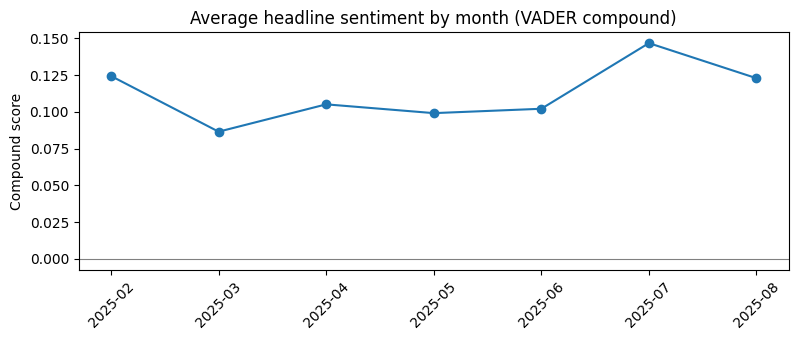

In [24]:
import matplotlib.pyplot as plt

trend = df.assign(Month=pd.to_datetime(df['Date'], errors='coerce').dt.to_period('M'))
monthly = trend.groupby('Month')['VADER_Compound'].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(monthly.index.astype(str), monthly.values, marker='o')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Average headline sentiment by month (VADER compound)')
ax.set_ylabel('Compound score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Business use case

**Scenario.** A financial news aggregator or an analyst desk receives hundreds of headlines a day and needs a fast first read.

**Value proposition.** The prototype tags each text with a sentiment score and a topic, flags the companies, indices and institutions it mentions, and gives a short summary or an answer to a specific question. That saves first-pass triage time for investment research and risk monitoring and helps an analyst decide which stories deserve a full read.

**Path to production.** Replace the static CSV with a licensed news feed (periodic ingestion), use a larger or fine-tuned model, and expose the API inside an existing research portal. The product could be licensed to a financial institution or sold as a per-seat subscription.

**Privacy and compliance.** Public news carries little personal data, but an enterprise version needs a retention policy, no logging of confidential client documents, and review under GDPR and the firm's own rules. Running the model locally, as here, keeps text on the machine. Anything used in client communication should go through compliance review.

**Limitations.**
- The tool is **not financial advice** and does not replace professional judgment.
- VADER is a general-purpose lexicon, not finance-tuned.
- TinyLlama is small: it can repeat itself, miss nuance or state things the text does not support.
- The dataset is small (about 50 distinct headlines), appears synthetic, and its sentiment and sector labels are unreliable, so reported numbers are sanity checks, not benchmarks.
- News and model outputs can both carry bias.

## Running the web app
The same pipeline is packaged as a Flask app (`app.py`, `templates/`, `static/`). See the repository README for install and run steps.